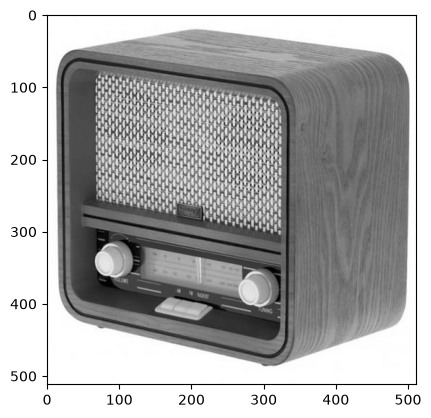

In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy

image = cv2.imread('input.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.resize(image_gray, (512, 512))

plt.imshow(image_gray, cmap="gray")
plt.show()

In [9]:
def haar_2d_step(img_block):
    A = img_block[0::2, 0::2]
    B = img_block[0::2, 1::2]
    C = img_block[1::2, 0::2]
    D = img_block[1::2, 1::2]
    
    LL = (A + B + C + D) / 4.0
    HL = (A - B + C - D) / 4.0
    LH = (A + B - C - D) / 4.0
    HH = (A - B - C + D) / 4.0
    
    top = np.hstack((LL, HL))
    bottom = np.hstack((LH, HH))
    return np.vstack((top, bottom))

def prepare_vis(haar_img, level):
    vis = np.abs(haar_img)
    scale = 2 ** level
    ll_h, ll_w = 512 // scale, 512 // scale
    
    mask = np.ones_like(vis)
    mask[0:ll_h, 0:ll_w] = 0
    vis = vis + (vis * mask * 4.0)
    return np.clip(vis, 0, 255).astype(np.uint8)

image_float = np.float32(image_gray)
h, w = image_float.shape

***Первая ступень***

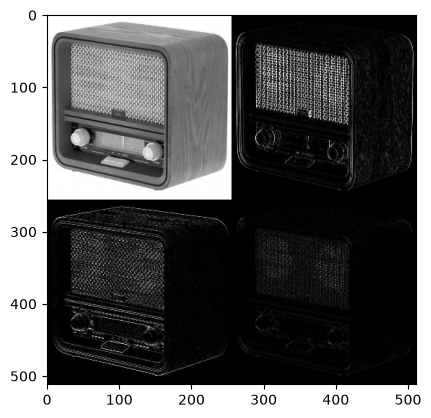

In [14]:
step1 = haar_2d_step(image_float)

plt.imshow(prepare_vis(step1, level=1), cmap="gray")
plt.show()

***Вторая ступень***

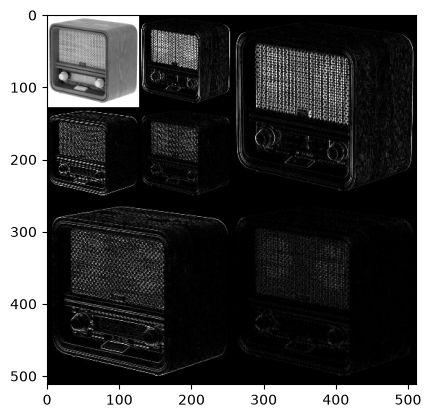

In [20]:
step2 = copy.deepcopy(step1)
step2[0:h//2, 0:w//2] = haar_2d_step(step2[0:h//2, 0:w//2])

plt.imshow(prepare_vis(step2, level=2), cmap="gray")
plt.show()

***Третья ступень***

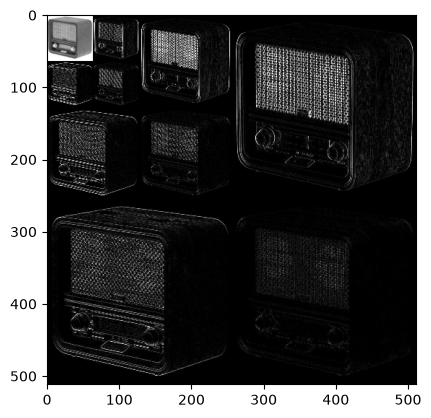

In [21]:
step3 = copy.deepcopy(step2)
step3[0:h//4, 0:w//4] = haar_2d_step(step3[0:h//4, 0:w//4])

plt.imshow(prepare_vis(step3, level=3), cmap="gray")
plt.show()